# Telluric-corrected KMOS data — inspection

Feb 10 – Aug 2026 OBs reduced with `make_standard = True` (`telluric_in_sof = True`).  
Jan 12–14 OBs (no standard star) are excluded automatically.

**Sections**
1. Inventory — OBs, files, IFU count
2. NaN channel map — telluric mask inferred from NaN patterns in the cubes
3. White-light images — per-IFU collapsed cube with aperture centre
4. Spectra — aperture-summed spectra with emission lines at catalogue redshift
5. S/N — rolling-MAD S/N estimate per IFU

In [26]:
import csv, glob, os, warnings
import pathlib
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits

PROCDIR      = 'kmos_ob_proc_server'   # downloaded Feb-Aug OBs (colon→dash filenames)
BAND         = 'YJ'
FITS_SUFFIX  = '_s_i_bkg2d_rv.fits'
APERTURE_BOX = 5
EDGE_MARGIN  = 4
NOISE_WINDOW = 51

# Skip Jan OBs – they were reduced without telluric correction
TELLURIC_FROM = '2026-02'

EMISSION_LINES = {
    '[OII]':      0.37270,
    'Hβ':         0.48627,
    '[OIII]4959': 0.49589,
    '[OIII]5007': 0.50082,
    'Hα':         0.65628,
    '[NII]6583':  0.65835,
    '[SII]6716':  0.67164,
}

ATMOS_BANDS = {
    'O2 B':   (0.685, 0.695),
    'H2O':    (0.715, 0.735),
    'O2 A':   (0.758, 0.772),
    'H2O ':   (0.805, 0.840),
    'H2O  ':  (0.880, 0.990),
    'H2O   ': (1.060, 1.110),
    'H2O    ':(1.130, 1.160),
    'H2O     ':(1.270, 1.320),
}

SCI_COLOR  = '#1f77b4'
NAN_COLOR  = '#ff7f0e'
TELL_COLOR = '#2ca02c'

plt.rcParams.update({
    'font.size': 10, 'axes.titlesize': 10, 'axes.titleweight': 'bold',
    'axes.labelsize': 9, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#555', 'axes.linewidth': 0.8,
    'axes.grid': True, 'axes.axisbelow': True,
    'grid.color': '#999', 'grid.alpha': 0.25, 'grid.linewidth': 0.6,
    'legend.framealpha': 0.85, 'legend.edgecolor': '0.85', 'legend.fontsize': 8,
    'figure.facecolor': 'white', 'savefig.facecolor': 'white',
})

In [27]:
def wave_axis(hdr, ax=3):
    n  = hdr[f'NAXIS{ax}']
    c1 = hdr.get(f'CRVAL{ax}', 0)
    d1 = hdr.get(f'CDELT{ax}', hdr.get(f'CD{ax}_{ax}', 1))
    p1 = hdr.get(f'CRPIX{ax}', 1)
    return c1 + (np.arange(n) + 1 - p1) * d1

def active_ifus(hdul):
    return [i for i in range(1, 25)
            if hdul[i].data is not None and np.ndim(hdul[i].data) == 3]

def _erode(finite, margin):
    inv = ~finite; eroded = inv.copy()
    for s in range(1, margin + 1):
        eroded[s:] |= inv[:-s]; eroded[:-s] |= inv[s:]
    return ~eroded

def aperture_spectrum(hdul, ifu, center, box=APERTURE_BOX, margin=EDGE_MARGIN):
    cube = np.array(hdul[ifu].data)
    py, px = center
    h = box // 2
    y0, y1 = max(py-h, 0), min(py+h+1, cube.shape[1])
    x0, x1 = max(px-h, 0), min(px+h+1, cube.shape[2])
    patch = cube[:, y0:y1, x0:x1].reshape(cube.shape[0], -1)
    valid = _erode(np.isfinite(patch), margin)
    cleaned = np.where(valid, patch, np.nan)
    ok = valid.any(axis=1)
    spec = np.full(cube.shape[0], np.nan)
    spec[ok] = np.nansum(cleaned[ok], axis=1)
    return wave_axis(hdul[ifu].header), spec

def _peak_from_image(img, min_nbr=0.05):
    ny, nx = img.shape
    flat = img.ravel()
    for idx in np.argsort(np.where(np.isfinite(flat), flat, -np.inf))[::-1]:
        v = flat[idx]
        if not np.isfinite(v) or v <= 0: break
        py, px = np.unravel_index(idx, img.shape)
        nbrs = [img[py+dy, px+dx] for dy in (-1,0,1) for dx in (-1,0,1)
                if (dy,dx) != (0,0) and 0<=py+dy<ny and 0<=px+dx<nx]
        nbrs = [n for n in nbrs if np.isfinite(n)]
        if nbrs and np.mean(nbrs) >= min_nbr*v: return (py, px)
    return np.unravel_index(np.nanargmax(img), img.shape)

def shade_atmos(ax, wave):
    wlo, whi = float(np.nanmin(wave)), float(np.nanmax(wave))
    for label, (lo, hi) in ATMOS_BANDS.items():
        if hi < wlo or lo > whi: continue
        ax.axvspan(max(lo, wlo), min(hi, whi), alpha=0.10, color='#888', lw=0, zorder=0)
        mid = (max(lo, wlo) + min(hi, whi)) / 2
        ax.text(mid, 1.01, label.strip(), transform=ax.get_xaxis_transform(),
                ha='center', va='bottom', fontsize=6, color='#555', clip_on=False)

def find_ob_files():
    """Return sorted list of (ob_name, [fits_paths]) for telluric-corrected OBs only."""
    result = []
    for ob_dir in sorted(glob.glob(os.path.join(PROCDIR, 'KMOS.*'))):
        ob = os.path.basename(ob_dir)
        date_part = ob[5:12]        # 'KMOS.2026-02-10T...' → '2026-02'
        if date_part < TELLURIC_FROM:
            continue
        files = sorted(
            glob.glob(os.path.join(ob_dir, 'science', f'*{FITS_SUFFIX}')) +
            glob.glob(os.path.join(ob_dir, f'*{FITS_SUFFIX}'))
        )
        if files:
            result.append((ob, files))
    return result

# redshift table
_Z = {}
_zcsv = pathlib.Path('scripts/target_redshifts.csv')
if _zcsv.exists():
    with open(_zcsv, newline='', encoding='utf-8') as _f:
        for _r in csv.DictReader(_f):
            if _r.get('redshift', '').strip():
                try:
                    _zv = float(_r['redshift'])
                except ValueError:
                    continue
                if abs(_zv - 9.9) < 0.05 or not (0 < _zv < 9):
                    continue          # sentinel 9.9 or other bad value
                _Z[(_r['field'].strip(), _r['arm_target_id'].strip())] = _zv
    print(f'Loaded {len(_Z)} redshifts')
else:
    print(f'WARNING: {_zcsv} not found — emission lines will not be marked')

# spec-z only subset — used for the stacked spectrum (photo-z scatter smears lines)
_Z_SPEC = {}
if _zcsv.exists():
    with open(_zcsv, newline='', encoding='utf-8') as _f:
        for _r in csv.DictReader(_f):
            if _r.get('redshift_type', '').strip() != 'spec':
                continue
            if not _r.get('redshift', '').strip():
                continue
            try:
                _zv = float(_r['redshift'])
            except ValueError:
                continue
            if abs(_zv - 9.9) < 0.05 or not (0 < _zv < 9):
                continue
            _Z_SPEC[(_r['field'].strip(), _r['arm_target_id'].strip())] = _zv
    print(f'Loaded {len(_Z_SPEC)} spec-z redshifts (used for stacked spectrum)')

def get_z(hdul, ifu):
    hdr0 = hdul[0].header
    field = (hdr0.get('ESO OBS TARG NAME') or '').strip()
    key   = f'ESO OCS ARM{ifu} NAME'
    tid   = str(hdr0[key]).strip() if key in hdr0 else None
    if not field or not tid: return None
    return _Z.get((field, tid))

def _target_key(hdul, ifu):
    hdr0 = hdul[0].header
    field = hdr0.get('ESO OBS TARG NAME')
    key   = f'ESO OCS ARM{ifu} NAME'
    return (field, str(hdr0[key])) if field and key in hdr0 else None

print('Building stack-derived source positions...')
OB_FILES = find_ob_files()
_stacks = {}
for ob, files in OB_FILES:
    for fpath in files:
        with fits.open(fpath) as h:
            for ifu in active_ifus(h):
                k = _target_key(h, ifu)
                if k is None: continue
                cube = np.array(h[ifu].data)
                valid = _erode(np.isfinite(cube), EDGE_MARGIN)
                img = np.nansum(np.where(valid, cube, np.nan), axis=0)
                _stacks[k] = img if k not in _stacks else np.nansum(
                    np.stack([_stacks[k], img]), axis=0)
STACK_CENTERS = {k: _peak_from_image(v) for k, v in _stacks.items()}

def get_center(hdul, ifu):
    k = _target_key(hdul, ifu)
    if k and k in STACK_CENTERS: return STACK_CENTERS[k]
    cube = np.array(hdul[ifu].data)
    img  = np.nansum(np.where(_erode(np.isfinite(cube), EDGE_MARGIN), cube, np.nan), axis=0)
    return _peak_from_image(img)

print(f'Done. {len(OB_FILES)} telluric-corrected OBs, {len(STACK_CENTERS)} stacked source positions.')

Loaded 95 redshifts
Loaded 38 spec-z redshifts (used for stacked spectrum)
Building stack-derived source positions...
Done. 29 telluric-corrected OBs, 62 stacked source positions.


In [28]:
print(f"{'OB':52s}  {'files':5s}  {'IFUs':4s}")
print('-' * 66)
total_files = 0
for ob, files in OB_FILES:
    with fits.open(files[0]) as h:
        n_ifu = len(active_ifus(h))
    print(f'{ob:52s}  {len(files):5d}  {n_ifu:4d}')
    total_files += len(files)
print('-' * 66)
print(f'Total: {len(OB_FILES)} OBs, {total_files} FITS files')

OB                                                    files  IFUs
------------------------------------------------------------------
KMOS.2026-02-10T04-52-11.148                              6    21
KMOS.2026-02-10T05-44-45.332                              6    21
KMOS.2026-02-10T06-48-00.201                              1    21
KMOS.2026-02-11T05-38-57.087                              6    21
KMOS.2026-02-11T06-31-26.207                              6    21
KMOS.2026-02-11T07-32-58.625                              6    21
KMOS.2026-02-11T08-24-09.387                              4    21
KMOS.2026-05-15T07-22-02.387                              6    21
KMOS.2026-05-15T08-42-38.698                              6    21
KMOS.2026-05-16T06-22-52.120                              6    21
KMOS.2026-05-16T07-43-38.766                              6    21
KMOS.2026-06-08T05-24-25.056                              6    21
KMOS.2026-06-08T06-47-02.127                              6    21
KMOS.2026

## 1 — NaN channel map

Fraction of spatial pixels that are NaN per wavelength channel, per OB.
High NaN fractions mark deep telluric absorption bands (T < 0.1) where the pipeline replaces
pixels with NaN rather than amplifying noise by dividing by near-zero transmission.
Known atmospheric bands are shaded grey for reference.

KMOS.2026-02-10T04-52-11.148:  λ 1.0000–1.3588 μm  |  channels >50 % NaN: 7.2%


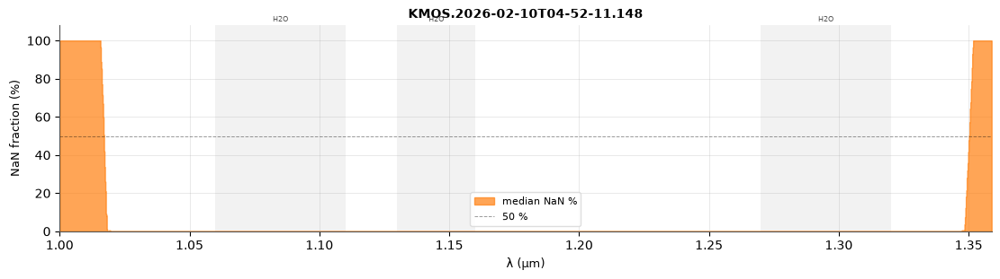

KMOS.2026-02-10T05-44-45.332:  λ 1.0000–1.3588 μm  |  channels >50 % NaN: 7.2%


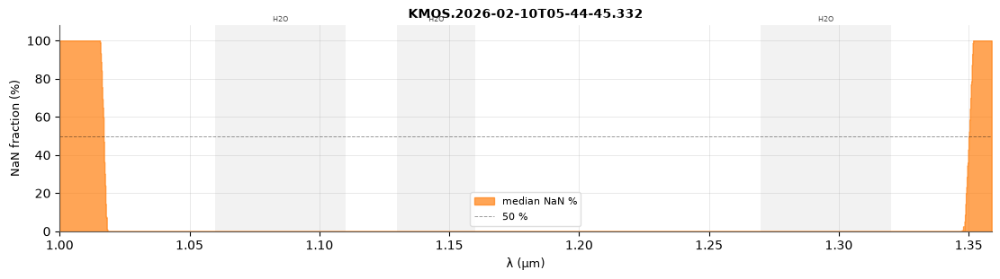

KMOS.2026-02-10T06-48-00.201:  λ 1.0000–1.3588 μm  |  channels >50 % NaN: 7.3%


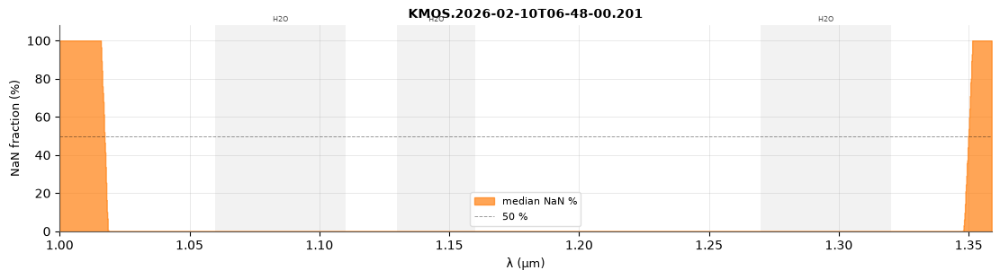

KMOS.2026-02-11T05-38-57.087:  λ 1.0000–1.3588 μm  |  channels >50 % NaN: 7.2%


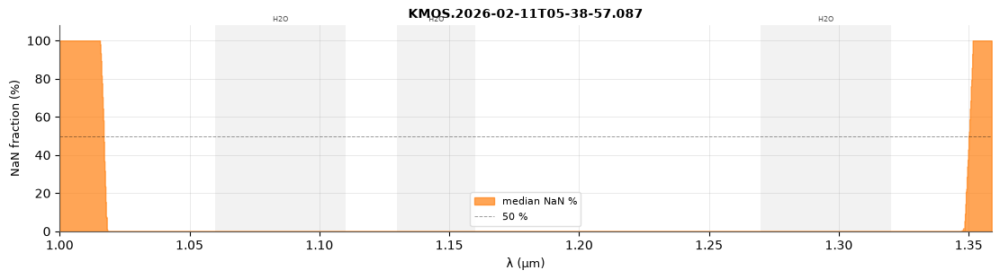

KMOS.2026-02-11T06-31-26.207:  λ 1.0000–1.3588 μm  |  channels >50 % NaN: 7.2%


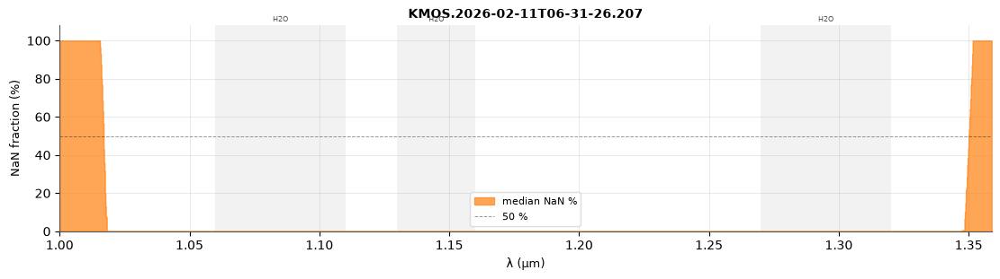

KMOS.2026-02-11T07-32-58.625:  λ 1.0000–1.3588 μm  |  channels >50 % NaN: 7.2%


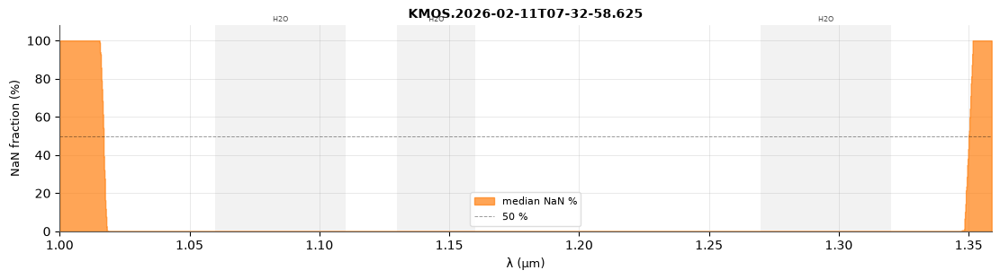

KMOS.2026-02-11T08-24-09.387:  λ 1.0000–1.3588 μm  |  channels >50 % NaN: 7.1%


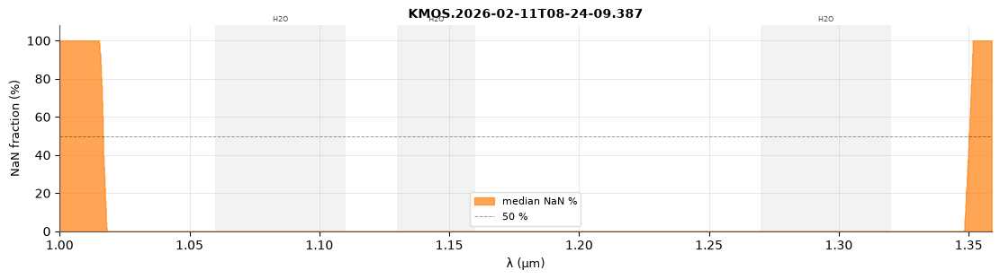

KMOS.2026-05-15T07-22-02.387:  λ 1.0000–1.3588 μm  |  channels >50 % NaN: 7.1%


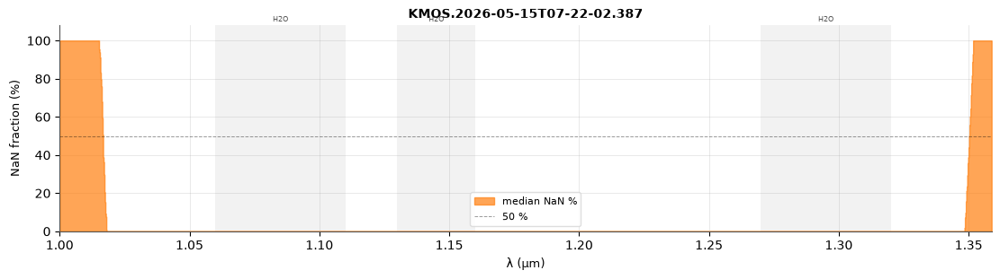

KMOS.2026-05-15T08-42-38.698:  λ 1.0000–1.3588 μm  |  channels >50 % NaN: 7.0%


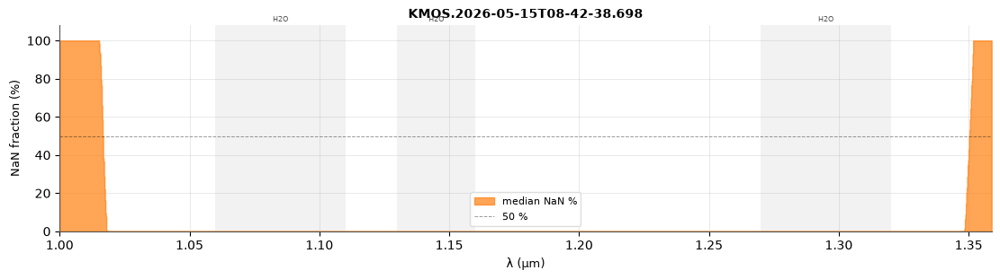

KMOS.2026-05-16T06-22-52.120:  λ 1.0000–1.3588 μm  |  channels >50 % NaN: 7.1%


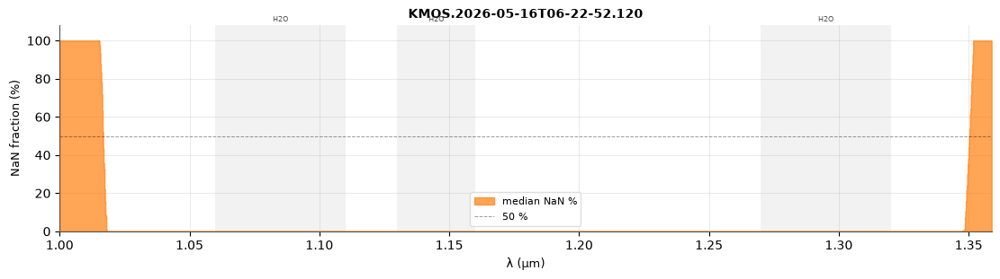

KMOS.2026-05-16T07-43-38.766:  λ 1.0000–1.3588 μm  |  channels >50 % NaN: 7.0%


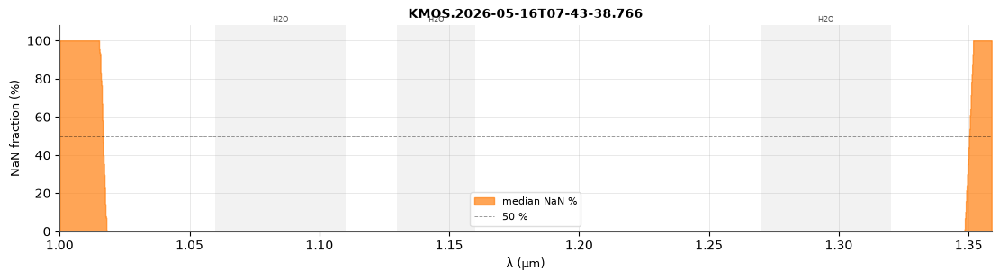

KMOS.2026-06-08T05-24-25.056:  λ 1.0000–1.3588 μm  |  channels >50 % NaN: 7.1%


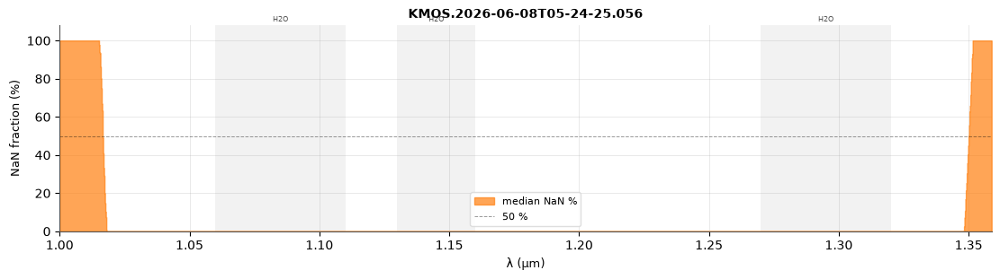

KMOS.2026-06-08T06-47-02.127:  λ 1.0000–1.3588 μm  |  channels >50 % NaN: 7.1%


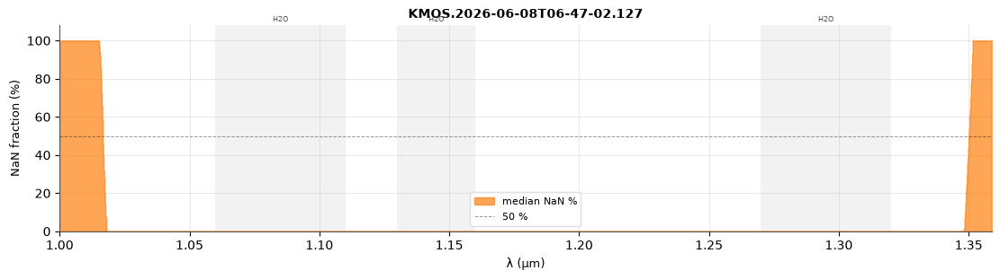

KMOS.2026-06-17T04-36-57.823:  λ 1.0000–1.3588 μm  |  channels >50 % NaN: 7.2%


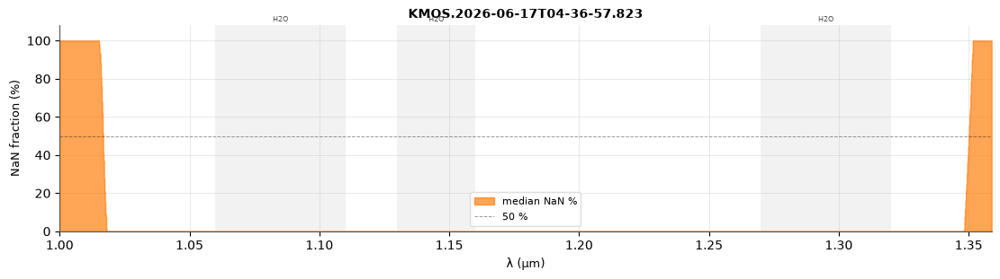

KMOS.2026-06-17T06-00-14.558:  λ 1.0000–1.3588 μm  |  channels >50 % NaN: 7.1%


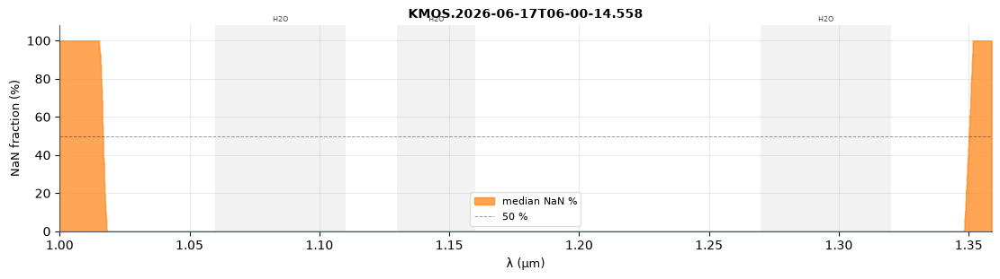

KMOS.2026-06-17T07-50-18.487:  λ 1.0000–1.3588 μm  |  channels >50 % NaN: 7.2%


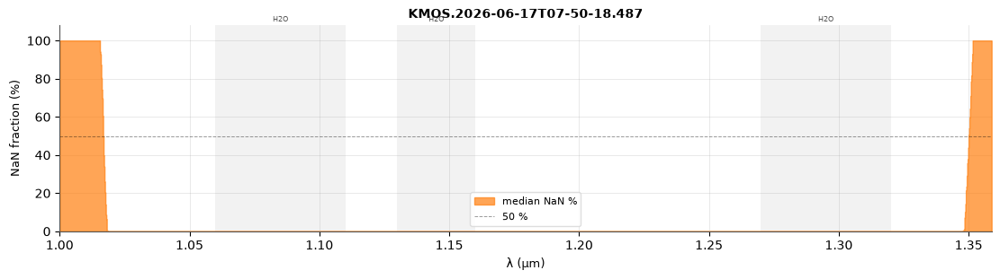

KMOS.2026-07-06T08-55-30.626:  λ 1.0000–1.3588 μm  |  channels >50 % NaN: 7.2%


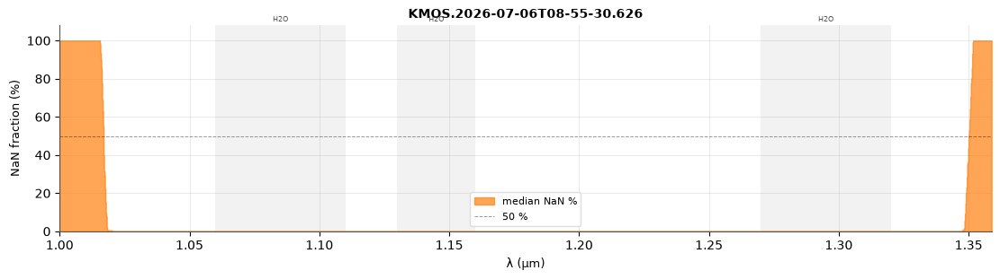

KMOS.2026-07-09T08-58-51.983:  λ 1.0000–1.3588 μm  |  channels >50 % NaN: 7.1%


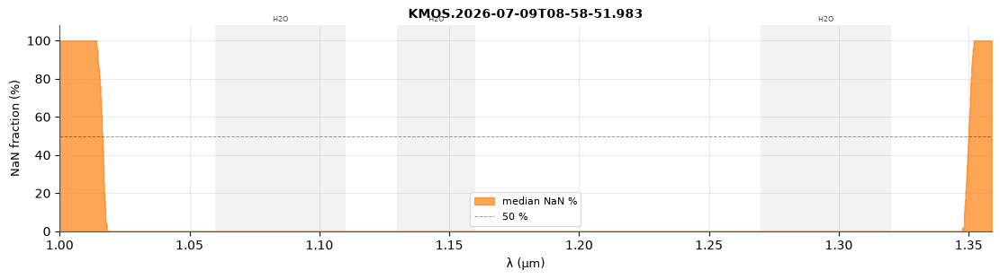

KMOS.2026-07-10T08-28-48.799:  λ 1.0000–1.3588 μm  |  channels >50 % NaN: 7.2%


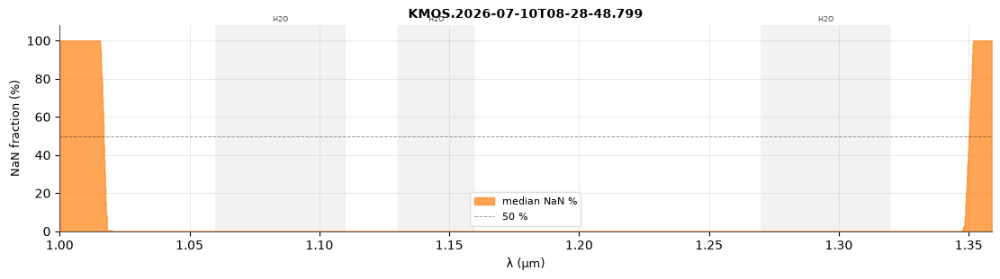

KMOS.2026-07-12T03-25-51.184:  λ 1.0000–1.3588 μm  |  channels >50 % NaN: 7.1%


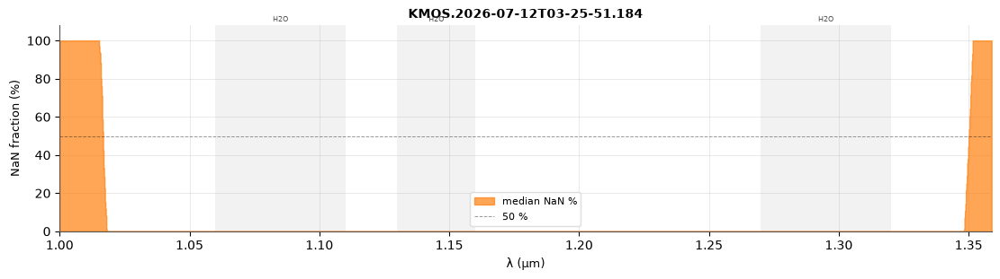

KMOS.2026-07-13T03-07-16.837:  λ 1.0000–1.3588 μm  |  channels >50 % NaN: 7.1%


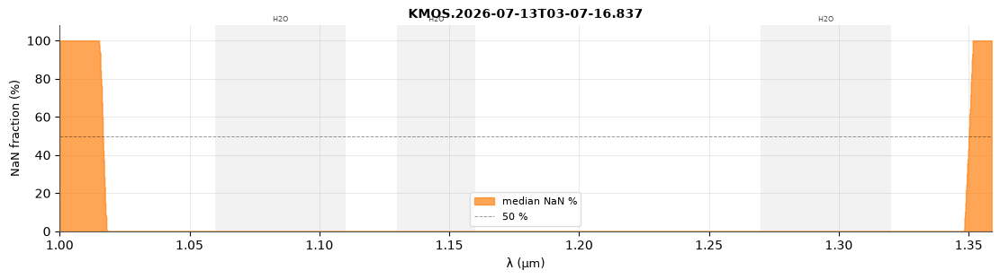

KMOS.2026-07-13T04-28-03.961:  λ 1.0000–1.3588 μm  |  channels >50 % NaN: 7.1%


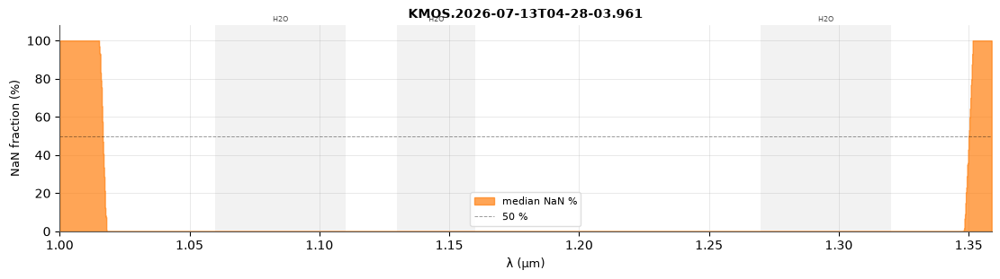

KMOS.2026-07-13T05-58-29.651:  λ 1.0000–1.3588 μm  |  channels >50 % NaN: 7.2%


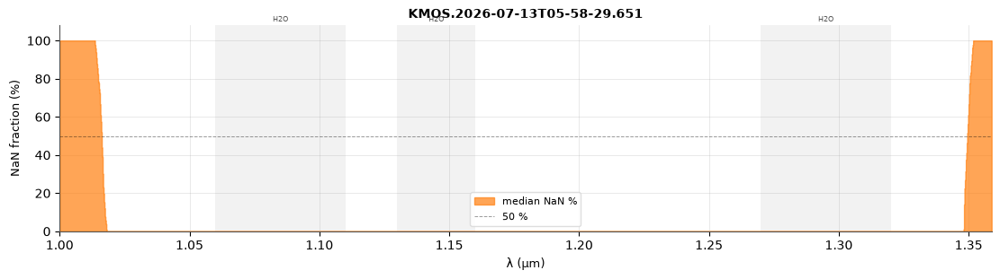

KMOS.2026-07-13T07-18-37.747:  λ 1.0000–1.3588 μm  |  channels >50 % NaN: 7.1%


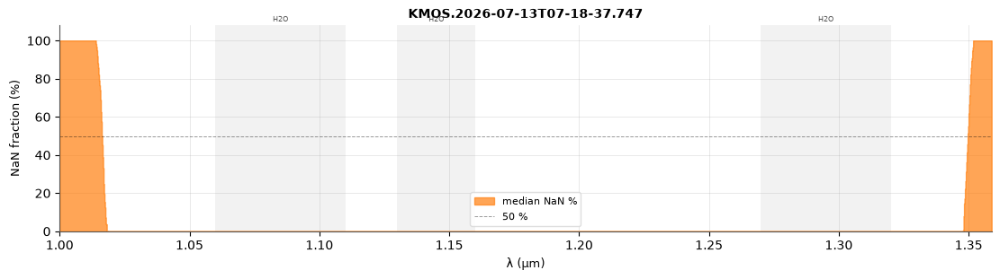

KMOS.2026-07-14T05-14-11.016:  λ 1.0000–1.3588 μm  |  channels >50 % NaN: 7.1%


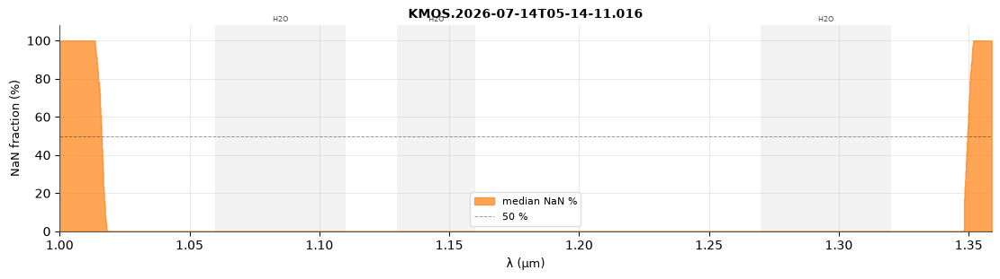

KMOS.2026-07-14T06-33-30.325:  λ 1.0000–1.3588 μm  |  channels >50 % NaN: 7.1%


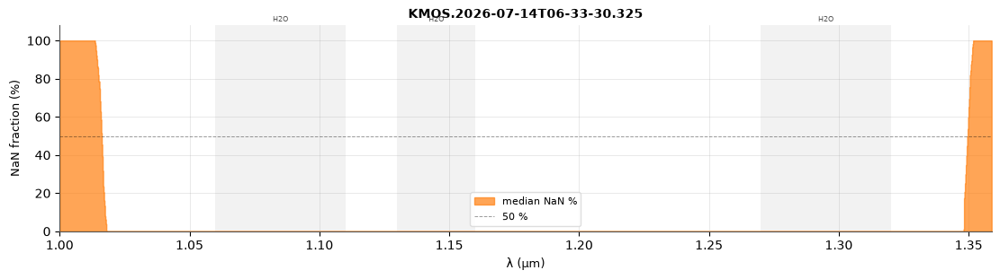

KMOS.2026-07-23T07-35-51.822:  λ 1.0000–1.3588 μm  |  channels >50 % NaN: 7.1%


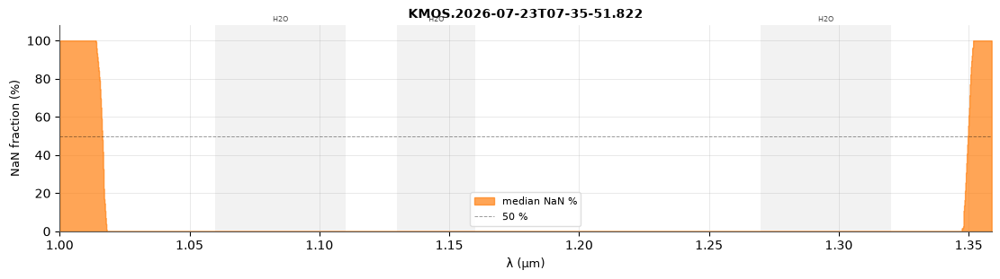

KMOS.2026-08-22T02-49-59.379:  λ 1.0000–1.3588 μm  |  channels >50 % NaN: 7.2%


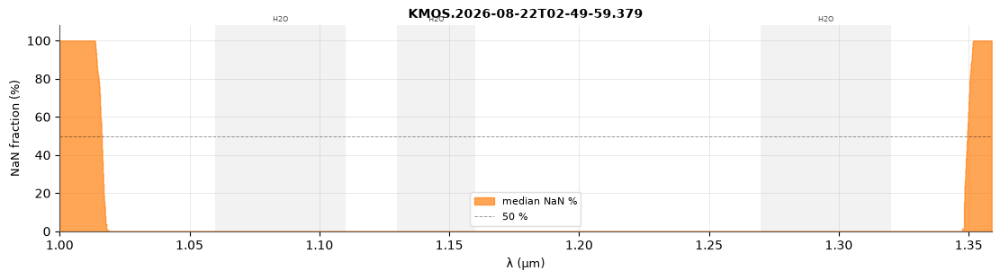

KMOS.2026-08-22T04-09-10.767:  λ 1.0000–1.3588 μm  |  channels >50 % NaN: 7.1%


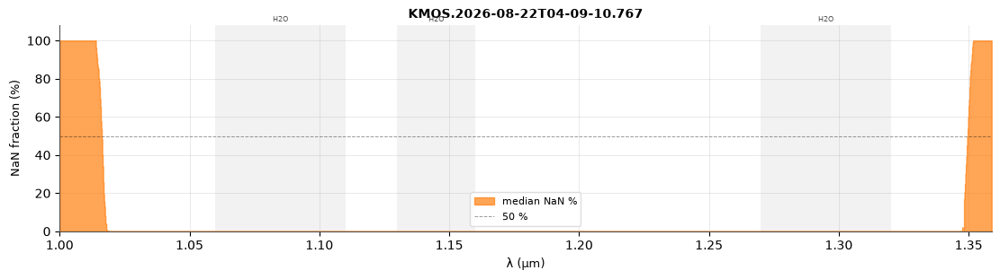

In [29]:
for ob, files in OB_FILES:
    nan_fracs, waves = [], None
    for fpath in files:
        with fits.open(fpath) as h:
            for ifu in active_ifus(h):
                cube = np.array(h[ifu].data, dtype=float)
                if waves is None:
                    waves = wave_axis(h[ifu].header)
                frac = np.mean(~np.isfinite(cube), axis=(1, 2))
                nan_fracs.append(frac)
    if not nan_fracs or waves is None:
        print(f'{ob}: no usable IFUs')
        continue
    med_frac = np.nanmedian(np.vstack(nan_fracs), axis=0)

    fig, ax = plt.subplots(figsize=(11, 3), constrained_layout=True)
    ax.fill_between(waves, 0, med_frac * 100,
                    color=NAN_COLOR, alpha=0.7, step='mid', label='median NaN %')
    shade_atmos(ax, waves)
    ax.axhline(50, color='k', lw=0.7, ls='--', alpha=0.4, label='50 %')
    ax.set_xlim(waves.min(), waves.max())
    ax.set_ylim(0, 108)
    ax.set_xlabel('λ (μm)'); ax.set_ylabel('NaN fraction (%)')
    ax.set_title(ob)
    ax.legend(fontsize=8)
    print(f'{ob}:  λ {waves.min():.4f}–{waves.max():.4f} μm  |  '
          f'channels >50 % NaN: {np.mean(med_frac > 0.5):.1%}')
    plt.show()

## 2 — White-light images

Each panel is a wavelength-collapsed (summed) image for one IFU.
The cyan cross marks the aperture centre used in Sections 3 and 4.

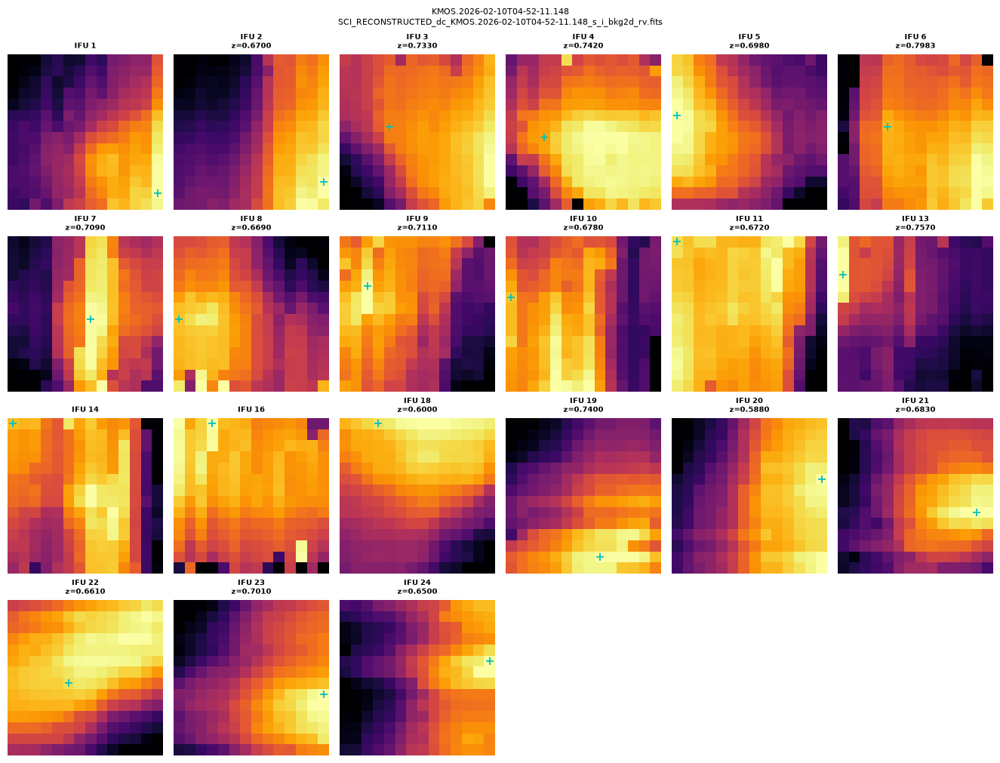

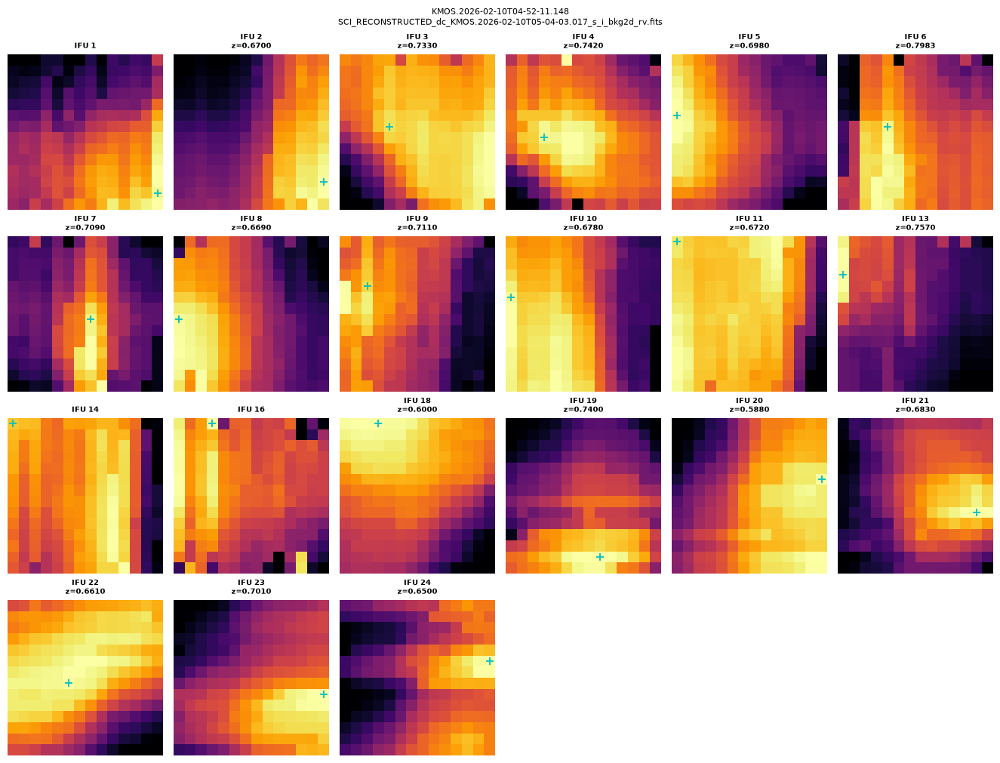

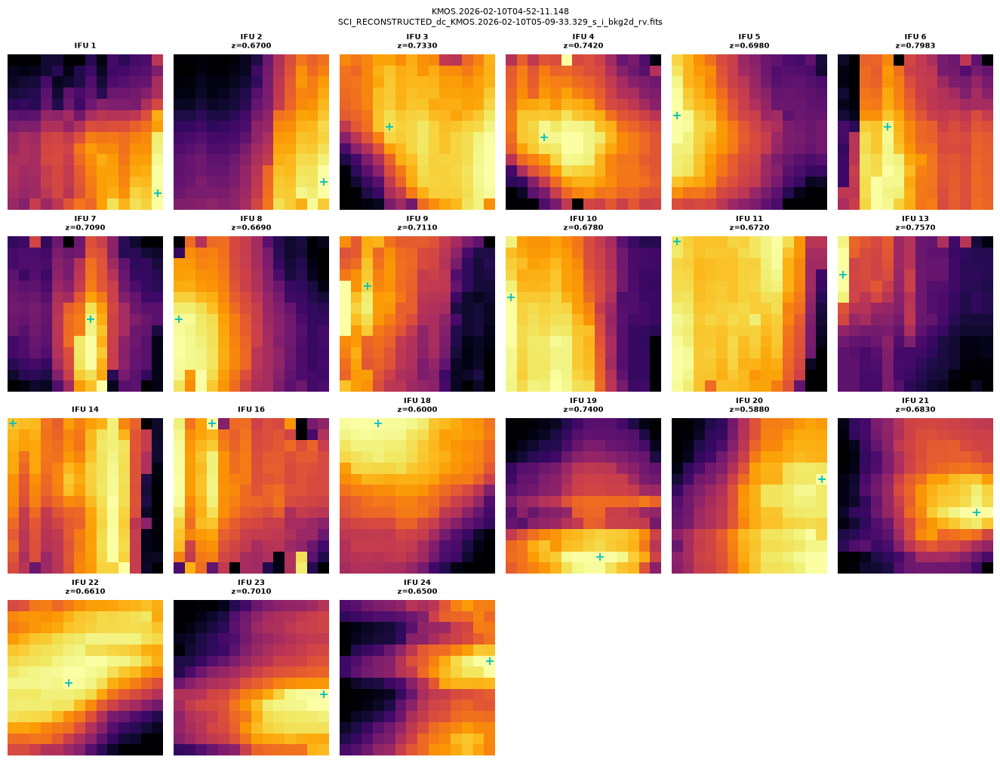

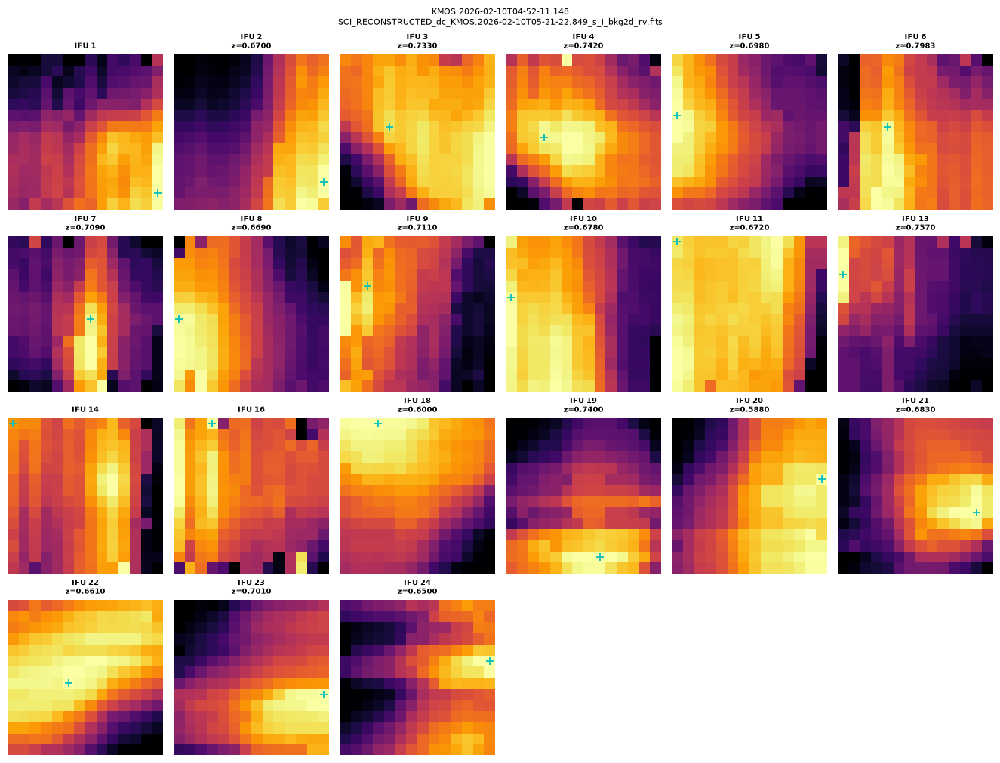

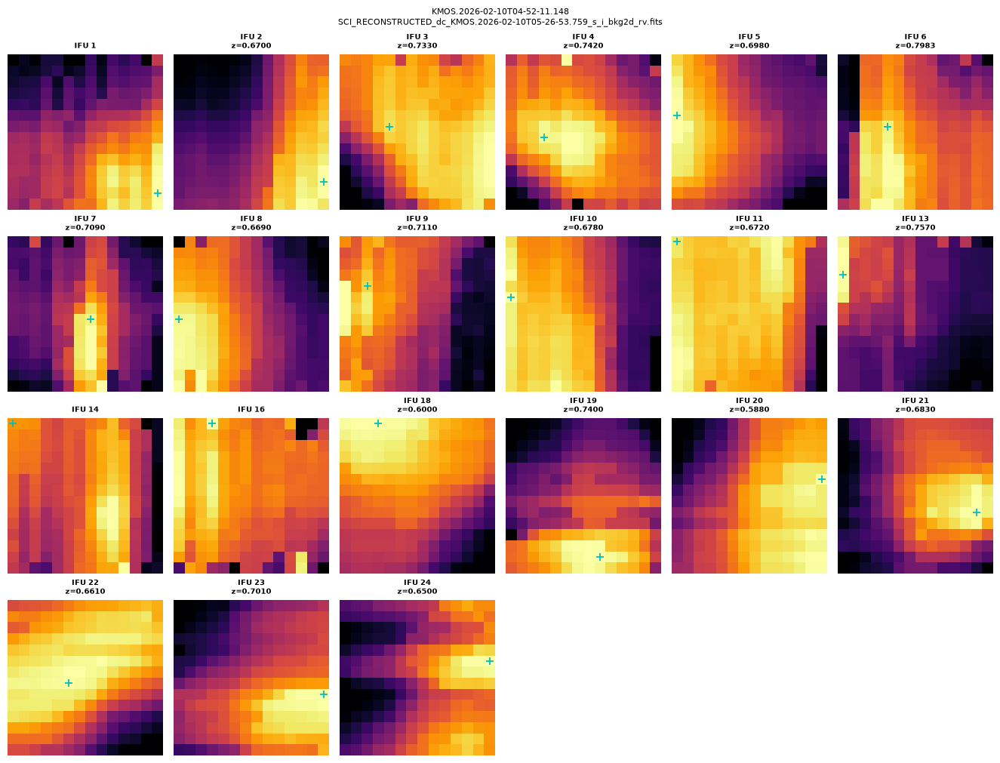

In [30]:
MAX_WL_FILES = 5
_wl_shown = 0
for ob, files in OB_FILES:
    if _wl_shown >= MAX_WL_FILES: break
    for fpath in files:
        if _wl_shown >= MAX_WL_FILES: break
        _wl_shown += 1
        fname = os.path.basename(fpath)
        with fits.open(fpath) as h:
            ifus = active_ifus(h)
            ncols = min(len(ifus), 6)
            nrows = int(np.ceil(len(ifus) / ncols))
            fig, axes = plt.subplots(nrows, ncols,
                                     figsize=(ncols * 2.2, nrows * 2.5),
                                     constrained_layout=True)
            fig.suptitle(f'{ob}\n{fname}', fontsize=8)
            axes_flat = np.array(axes).ravel()
            for ax_i, ifu in enumerate(ifus):
                ax = axes_flat[ax_i]
                cube = np.array(h[ifu].data, dtype=float)
                valid = _erode(np.isfinite(cube), EDGE_MARGIN)
                img = np.nansum(np.where(valid, cube, np.nan), axis=0)
                ctr = get_center(h, ifu)
                z = get_z(h, ifu)
                vlo, vhi = np.nanpercentile(img[img > 0], [2, 99]) if (img > 0).any() else (0, 1)
                ax.imshow(img, origin='lower', cmap='inferno',
                          vmin=vlo, vmax=vhi, aspect='equal', interpolation='nearest')
                ax.plot(ctr[1], ctr[0], 'c+', ms=7, mew=1.3)
                title = f'IFU {ifu}'
                if z: title += f'\nz={z:.4f}'
                ax.set_title(title, fontsize=7)
                ax.axis('off')
            for ax in axes_flat[len(ifus):]:
                ax.set_visible(False)
            plt.show()

## 3 — Aperture spectra

Aperture-summed spectra (5×5 spaxel box centred on the stacked-cube peak).
Dotted vertical lines = emission lines at the catalogue redshift.
Grey shading = known atmospheric absorption bands.

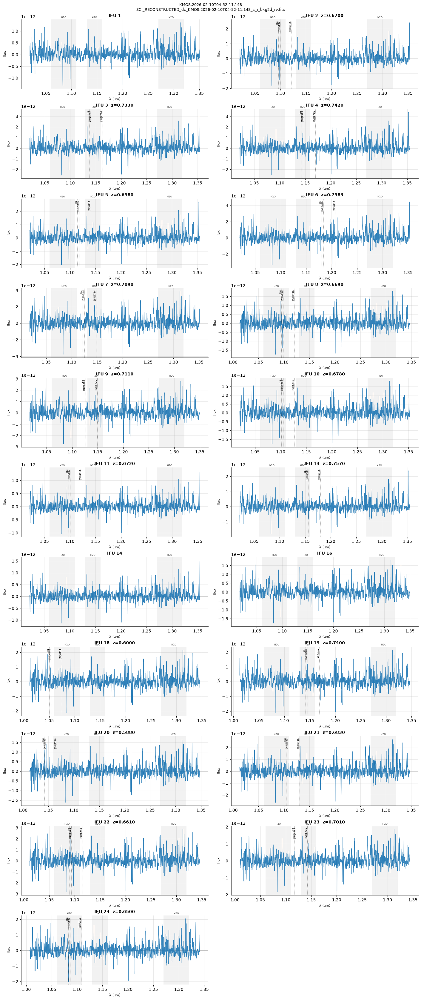

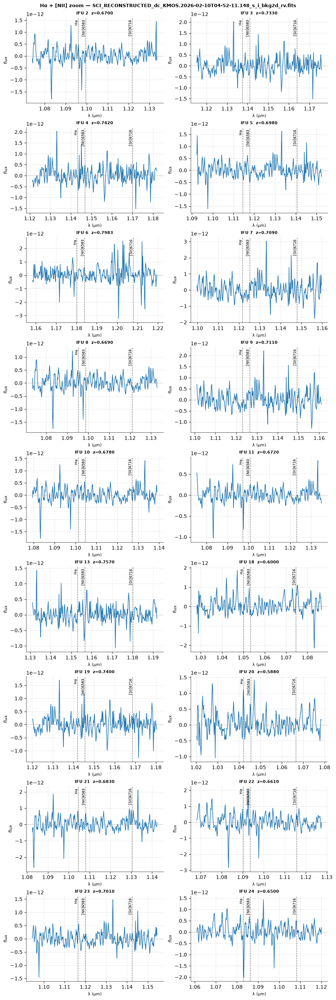

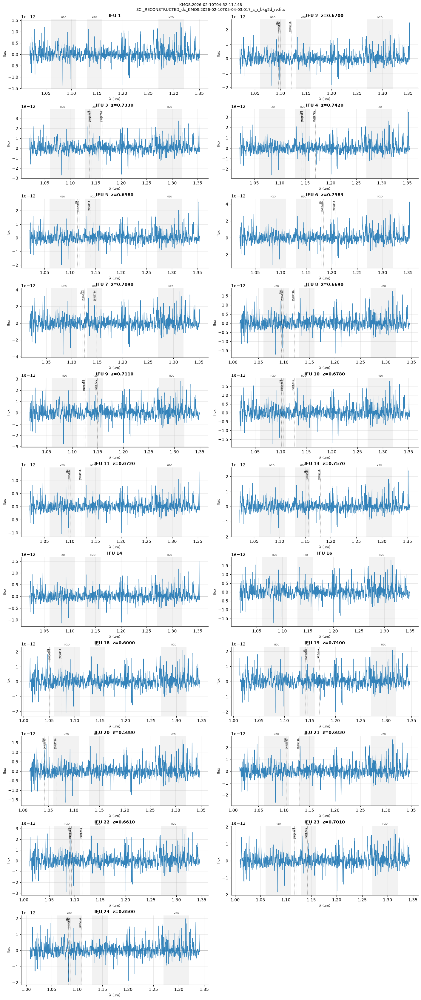

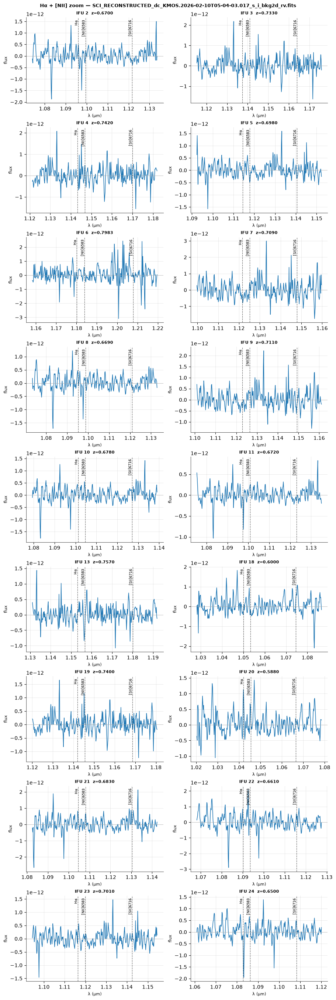

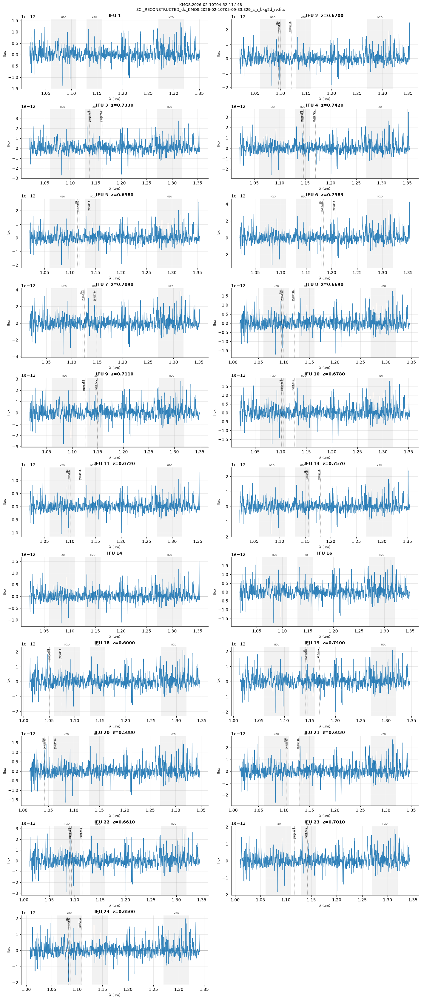

...

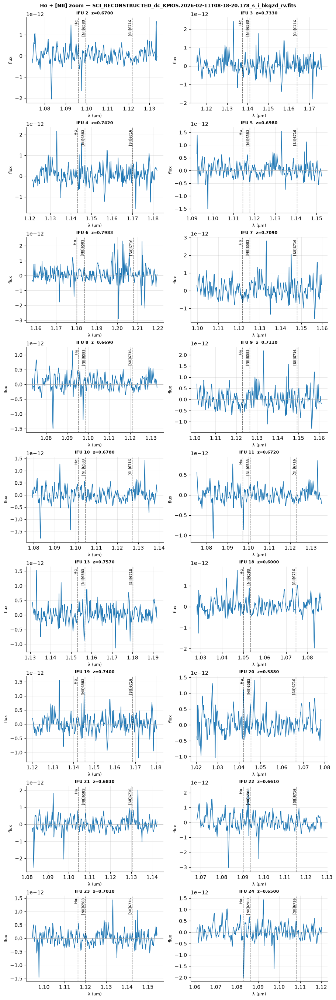

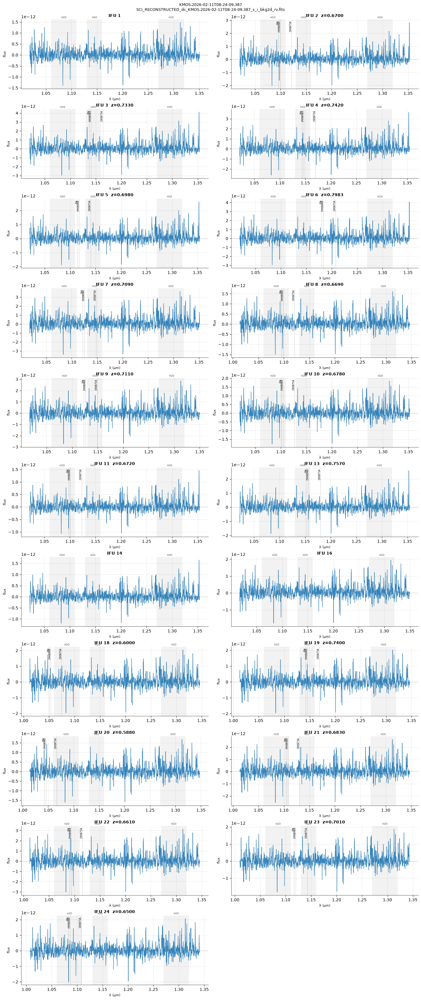

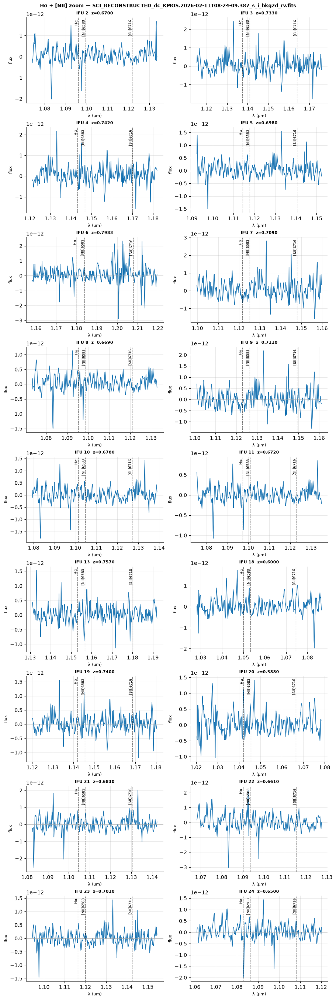

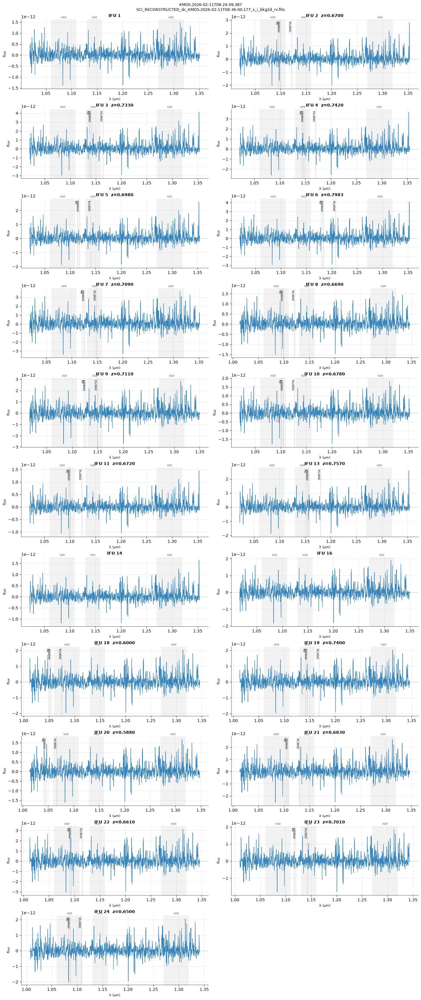

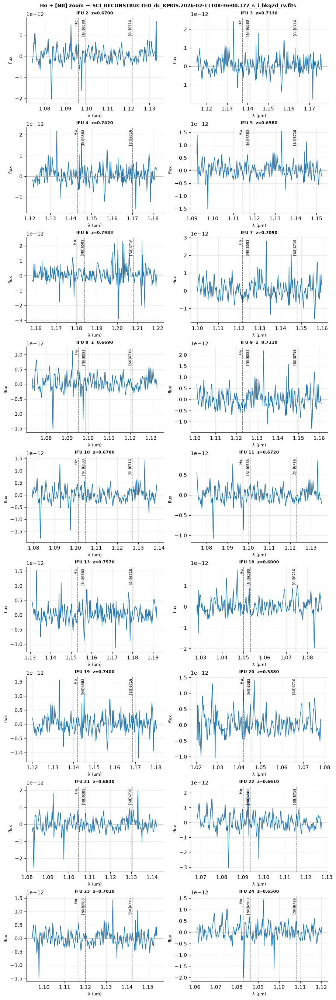

In [ ]:
for ob, files in OB_FILES:
    for fpath in files:
        fname = os.path.basename(fpath)
        with fits.open(fpath) as h:
            ifus = active_ifus(h)
            ncols = 2
            nrows = int(np.ceil(len(ifus) / ncols))
            fig, axes = plt.subplots(nrows, ncols,
                                     figsize=(ncols * 7, nrows * 3),
                                     constrained_layout=True)
            fig.suptitle(f'{ob}\n{fname}', fontsize=9, y=1.01)
            axes_flat = np.array(axes).ravel()
            for ax_i, ifu in enumerate(ifus):
                ax = axes_flat[ax_i]
                ctr = get_center(h, ifu)
                wave, spec = aperture_spectrum(h, ifu, ctr)
                z = get_z(h, ifu)
                ax.plot(wave, spec, color=SCI_COLOR, lw=0.9, alpha=0.9)
                ax.axhline(0, color='#aaa', lw=0.5, zorder=0)
                shade_atmos(ax, wave)
                if z:
                    ylims = ax.get_ylim()
                    for lname, lrest in EMISSION_LINES.items():
                        lobs = lrest * (1 + z)
                        if wave.min() <= lobs <= wave.max():
                            ax.axvline(lobs, color='k', lw=0.8, alpha=0.45, ls=':')
                            ax.text(lobs, 0.97, lname,
                                    transform=ax.get_xaxis_transform(),
                                    rotation=90, ha='right', va='top',
                                    fontsize=6, color='k', clip_on=True)
                title = f'IFU {ifu}'
                if z: title += f'  z={z:.4f}'
                ax.set_title(title)
                ax.set_xlabel('λ (μm)', fontsize=8)
                ax.set_ylabel('flux', fontsize=8)
            for ax in axes_flat[len(ifus):]:
                ax.set_visible(False)
            plt.show()
            # ── Hα / [NII] zoom panels ──────────────────────────────────────
            _ha_rest  = EMISSION_LINES['Hα']
            _nii_rest = EMISSION_LINES['[NII]6583']
            _sii_rest = EMISSION_LINES['[SII]6716']
            _zoom_pairs = []
            for _ifu in ifus:
                _z = get_z(h, _ifu)
                if _z is None:
                    continue
                _ha_obs = _ha_rest * (1 + _z)
                # check the band covers Ha region for this redshift
                _ctr_tmp = get_center(h, _ifu)
                _w_tmp, _ = aperture_spectrum(h, _ifu, _ctr_tmp)
                if _w_tmp.min() < _ha_obs < _w_tmp.max():
                    _zoom_pairs.append((_ifu, _z))
            if _zoom_pairs:
                _nzc = min(len(_zoom_pairs), 2)
                _nzr = int(np.ceil(len(_zoom_pairs) / _nzc))
                _fig2, _axes2 = plt.subplots(_nzr, _nzc,
                                             figsize=(_nzc * 4.5, _nzr * 3),
                                             constrained_layout=True)
                _fig2.suptitle(f'Hα + [NII] zoom — {fname}', fontsize=9, fontweight='bold')
                _axes2_flat = np.array(_axes2).ravel()
                for _ai, (_ifu, _z) in enumerate(_zoom_pairs):
                    _ax = _axes2_flat[_ai]
                    _ctr2 = get_center(h, _ifu)
                    _w2, _s2 = aperture_spectrum(h, _ifu, _ctr2)
                    _lo = _ha_rest * (1 + _z) - 0.022
                    _hi = _sii_rest * (1 + _z) + 0.012
                    _mask = (_w2 >= _lo) & (_w2 <= _hi)
                    if _mask.sum() < 5:
                        _ax.text(0.5, 0.5, 'out of range', transform=_ax.transAxes,
                                 ha='center', va='center', fontsize=8, color='#888')
                    else:
                        _ax.plot(_w2[_mask], _s2[_mask], color=SCI_COLOR, lw=1.1)
                        _ax.axhline(0, color='#aaa', lw=0.5)
                        for _ln, _lr in EMISSION_LINES.items():
                            _lobs = _lr * (1 + _z)
                            if _lo <= _lobs <= _hi:
                                _ax.axvline(_lobs, color='k', lw=0.9, alpha=0.55, ls='--')
                                _ax.text(_lobs, 0.97, _ln,
                                         transform=_ax.get_xaxis_transform(),
                                         rotation=90, ha='right', va='top',
                                         fontsize=7, color='k', clip_on=True)
                        _ax.set_xlabel('λ (μm)', fontsize=8)
                        _ax.set_ylabel('flux', fontsize=8)
                    _ax.set_title(f'IFU {_ifu}  z={_z:.4f}', fontsize=8)
                for _ax in _axes2_flat[len(_zoom_pairs):]:
                    _ax.set_visible(False)
                plt.show()

## 4 — Rest-frame stacked spectrum

In [ ]:
print('Building rest-frame stacked spectrum (spec-z only)...')

# ── Grand stack: all spec-z IFUs shifted to rest frame ────────────────────────
REST_GRID = np.arange(0.620, 0.751, 0.0002)
N_WAVE    = len(REST_GRID)
specs_list = []
# Also collect per-target spectra in observed frame
per_target = {}  # (field, tid, z) -> list of (wave_obs, spec)

for ob, files in OB_FILES:
    for fpath in files:
        with fits.open(fpath) as h:
            hdr0 = h[0].header
            field = (hdr0.get('ESO OBS TARG NAME') or '').strip()
            for ifu in active_ifus(h):
                key_hdr = f'ESO OCS ARM{ifu} NAME'
                tid = str(hdr0[key_hdr]).strip() if key_hdr in hdr0 else None
                if not field or not tid:
                    continue
                z = _Z_SPEC.get((field, tid))
                if z is None:
                    continue
                ctr = get_center(h, ifu)
                wave, spec = aperture_spectrum(h, ifu, ctr)
                # store for per-target panel
                per_target.setdefault((field, tid, z), []).append((wave.copy(), spec.copy()))
                # add to grand stack
                wave_rest = wave / (1.0 + z)
                in_grid = (wave_rest >= REST_GRID[0]) & (wave_rest <= REST_GRID[-1])
                if in_grid.sum() < 20:
                    continue
                valid = spec[in_grid & np.isfinite(spec)]
                if valid.size < 20:
                    continue
                noise = np.nanmedian(np.abs(valid - np.nanmedian(valid))) * 1.4826
                if noise == 0:
                    continue
                spec_n = spec / noise
                ok = np.isfinite(spec_n) & in_grid
                if ok.sum() < 20:
                    continue
                interp = np.interp(REST_GRID, wave_rest[ok], spec_n[ok],
                                   left=np.nan, right=np.nan)
                if len(interp) == N_WAVE:
                    specs_list.append(interp.astype(float))

n_contrib   = len(specs_list)
n_targets   = len(per_target)
print(f'Stacked {n_contrib} spec-z IFU spectra from {n_targets} unique targets.')

# ── Plot 1: grand rest-frame composite ────────────────────────────────────────
if n_contrib > 0:
    specs_2d = np.empty((n_contrib, N_WAVE), dtype=float)
    for i, s in enumerate(specs_list):
        specs_2d[i] = s
    stack    = np.nanmedian(specs_2d, axis=0)
    stack_lo = np.nanpercentile(specs_2d, 16, axis=0)
    stack_hi = np.nanpercentile(specs_2d, 84, axis=0)

    fig, ax = plt.subplots(figsize=(11, 4), constrained_layout=True)
    ax.fill_between(REST_GRID, stack_lo, stack_hi,
                    color=SCI_COLOR, alpha=0.20, lw=0, label='16–84th pct')
    ax.plot(REST_GRID, stack, color=SCI_COLOR, lw=1.0, alpha=0.92,
            label=f'spec-z median stack  N={n_contrib}')
    ax.axhline(0, color='#aaa', lw=0.5, ls='--', zorder=0)
    for lname, lrest in EMISSION_LINES.items():
        if REST_GRID[0] <= lrest <= REST_GRID[-1]:
            ax.axvline(lrest, color='#d62728', lw=1.0, alpha=0.6, ls=':')
            ax.text(lrest, 0.97, lname,
                    transform=ax.get_xaxis_transform(),
                    rotation=90, ha='right', va='top',
                    fontsize=7, color='#d62728', clip_on=True)
    ax.set_xlabel('λ_rest (μm)', fontsize=9)
    ax.set_ylabel('median S/N stack', fontsize=9)
    ax.set_title(f'Rest-frame composite — {n_contrib} spectra, {n_targets} spec-z targets',
                 fontweight='bold')
    ax.legend(framealpha=0.85)
    plt.show()

# ── Plot 2: per-target co-added spectrum in observed frame ────────────────────
for (field, tid, z), exposures in sorted(per_target.items(), key=lambda x: x[0][2]):
    # co-add all exposures for this target (noise-weighted mean in observed frame)
    # all exposures share the same wavelength grid
    wave_ref = exposures[0][0]
    all_specs = np.array([s for w, s in exposures], dtype=float)
    # per-exposure noise
    noises = []
    for i in range(len(all_specs)):
        valid_i = all_specs[i][np.isfinite(all_specs[i])]
        n_i = np.nanmedian(np.abs(valid_i - np.nanmedian(valid_i))) * 1.4826 if valid_i.size else 0
        noises.append(n_i)
    noises = np.array(noises)
    # weighted sum: w_i = 1/sigma_i^2, skip zero-noise exposures
    good = noises > 0
    if not good.any():
        continue
    weights = 1.0 / noises[good]**2
    weighted = np.nansum(all_specs[good] * weights[:, None], axis=0) / weights.sum()
    noise_coadd = 1.0 / np.sqrt(weights.sum())

    fig, ax = plt.subplots(figsize=(11, 3.5), constrained_layout=True)
    ax.plot(wave_ref, weighted, color=SCI_COLOR, lw=0.9,
            label=f'co-add  N={good.sum()} exp  σ={noise_coadd:.2e}')
    ax.axhline(0, color='#aaa', lw=0.5, ls='--', zorder=0)
    shade_atmos(ax, wave_ref)
    # mark expected emission lines in observed frame
    for lname, lrest in EMISSION_LINES.items():
        lobs = lrest * (1 + z)
        if wave_ref.min() <= lobs <= wave_ref.max():
            ax.axvline(lobs, color='#d62728', lw=1.0, alpha=0.6, ls=':')
            ax.text(lobs, 0.97, lname,
                    transform=ax.get_xaxis_transform(),
                    rotation=90, ha='right', va='top',
                    fontsize=7, color='#d62728', clip_on=True)
    ax.set_xlabel('λ_obs (μm)', fontsize=9)
    ax.set_ylabel('flux (co-add)', fontsize=9)
    ax.set_title(f'Co-added spectrum — target {tid}  z={z:.4f}  ({field})',
                 fontweight='bold')
    ax.legend(framealpha=0.85)
    plt.show()


## 5 — S/N per IFU

Rolling-MAD S/N estimate. Spikes at emission-line positions indicate detections.
Dips in the grey-shaded atmospheric bands show where noise is amplified after telluric correction.

In [ ]:
def rolling_mad_snr(spec, window=NOISE_WINDOW):
    half = window // 2
    padded = np.pad(spec, half, mode='edge')
    wins = np.lib.stride_tricks.sliding_window_view(padded, window)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', RuntimeWarning)
        trend = np.nanmedian(wins, axis=1)
        mad   = np.nanmedian(np.abs(wins - trend[:, None]), axis=1)
    with np.errstate(divide='ignore', invalid='ignore'):
        return spec / (1.4826 * mad)

for ob, files in OB_FILES:
    for fpath in files:
        fname = os.path.basename(fpath)
        with fits.open(fpath) as h:
            ifus = active_ifus(h)
            ncols = 2
            nrows = int(np.ceil(len(ifus) / ncols))
            fig, axes = plt.subplots(nrows, ncols,
                                     figsize=(ncols * 7, nrows * 3),
                                     constrained_layout=True)
            fig.suptitle(f'{ob}  —  S/N\n{fname}', fontsize=9, y=1.01)
            axes_flat = np.array(axes).ravel()
            for ax_i, ifu in enumerate(ifus):
                ax = axes_flat[ax_i]
                ctr = get_center(h, ifu)
                wave, spec = aperture_spectrum(h, ifu, ctr)
                snr = rolling_mad_snr(spec)
                z = get_z(h, ifu)
                ax.plot(wave, snr, color=SCI_COLOR, lw=0.9)
                ax.axhline(0, color='#aaa', lw=0.5, zorder=0)
                shade_atmos(ax, wave)
                if z:
                    for lname, lrest in EMISSION_LINES.items():
                        lobs = lrest * (1 + z)
                        if wave.min() <= lobs <= wave.max():
                            ax.axvline(lobs, color='k', lw=0.7, alpha=0.4, ls=':')
                            ax.text(lobs, 0.97, lname,
                                    transform=ax.get_xaxis_transform(),
                                    rotation=90, ha='right', va='top',
                                    fontsize=6, color='k', clip_on=True)
                title = f'IFU {ifu}'
                if z: title += f'  z={z:.4f}'
                ax.set_title(title)
                ax.set_xlabel('λ (μm)', fontsize=8)
                ax.set_ylabel('S/N', fontsize=8)
            for ax in axes_flat[len(ifus):]:
                ax.set_visible(False)
            plt.show()